# Evaluación 03 — Detección automática de maquinaria de construcción con YOLO26n
**Equipo:** Mathis Marsault · Julien Martinat · Louis Maillet  
**Universidad Bernardo O'Higgins — Machine Learning** · Dr. Eliecer Peña Ancavil  
**Fecha de los experimentos:** 29 de octubre de 2026 · **Estado: ejecutado en Google Colab T4**

**Objetivo:** detectar las clases `EXCAVATORS`, `dump truck` y `wheel loader`. Transfer learning (8 épocas, `freeze=10`) y fine tuning (5 épocas, `freeze=0`, AdamW) entrenados por el equipo con el conjunto **Excavators v2** (Roboflow Universe, CC BY 4.0). Split de trabajo: **2 406 Train / 144 Validation / 82 Test**. Las transformaciones realizadas para reducir fugas están documentadas en `docs/AUDITORIA_DATASET.md`.

**Regla previamente fijada:** elegir según mayor mAP50-95 en Validation. **Modelo elegido: transfer learning** (0,712923 frente a 0,707573); **Test evaluado una única vez** (mAP50=0,865897; mAP50-95=0,716560). No reconfigurar basándose en Test.

**Reproducción:** ejecutar las celdas en orden en Colab T4. Subir el ZIP v2 original cuando se solicite; la limpieza se hace antes de entrenar. Las fotografías y videos externos se suben en su sección. El repositorio conserva los scripts y un informe técnico con las cifras verificadas: https://github.com/MamatorHack/YOLO-Maquinaria-UBO.

> Las salidas numéricas y gráficas guardadas corresponden a la ejecución real; se han eliminado solo registros repetitivos y recursos incrustados de gran tamaño del archivo publicado en GitHub. Se enlazan las figuras originales de Test. Los tres pesos `.pt` se entregan por separado y no se incluyen en el notebook.

## 1 — Dependencias, GPU y repositorio

In [1]:
%pip install -q ultralytics kagglehub pyyaml pandas matplotlib pillow pytest
import os, sys, shutil, json, zipfile, subprocess
from pathlib import Path
import torch
assert torch.cuda.is_available(), "Activar GPU T4 en Entorno de ejecución > Cambiar tipo de entorno de ejecución"
print("GPU:", torch.cuda.get_device_name(0))
if not Path("/content/YOLO-Maquinaria-UBO/src/yolo_ubo.py").exists():
    subprocess.run(["git", "clone", "https://github.com/MamatorHack/YOLO-Maquinaria-UBO.git", "/content/YOLO-Maquinaria-UBO"], check=True)
ROOT = Path("/content/YOLO-Maquinaria-UBO")
sys.path.insert(0, str(ROOT))
from src.yolo_ubo import *
%cd /content/YOLO-Maquinaria-UBO

GPU: Tesla T4
/content/YOLO-Maquinaria-UBO


## 2 — Configuración del experimento
**No modificar después de ver Test.** Dos etapas obligatorias: congelar backbone en transfer learning, descongelar todo en fine tuning. Estos valores son una configuración inicial adaptada a las limitaciones de Colab gratuito.

In [2]:
SEED = 42
IMGSZ = 416
BATCH = 16  # Reducir a 8 si ocurre CUDA out of memory
TRAIN_FRACTION = 1.0  # Reducir (ej. 0.5) si el tiempo Colab no alcanza
EPOCHS_TRANSFER = 8
EPOCHS_FINETUNE = 5
BASE_WEIGHTS = "yolo26n.pt"  # alternativa permitida: yolo11n.pt
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50
CLASES = ("EXCAVATORS", "dump truck", "wheel loader")
Path("results").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
import random
random.seed(SEED)
print("Configuración:", {k:v for k,v in globals().copy().items() if k in ("IMGSZ","BATCH","TRAIN_FRACTION","EPOCHS_TRANSFER","EPOCHS_FINETUNE","BASE_WEIGHTS","SEED")})

Configuración: {'SEED': 42, 'IMGSZ': 416, 'BATCH': 16, 'TRAIN_FRACTION': 1.0, 'EPOCHS_TRANSFER': 8, 'EPOCHS_FINETUNE': 5, 'BASE_WEIGHTS': 'yolo26n.pt'}


## 3 — Importación y limpieza reproducible del dataset
Se usa la exportación original YOLOv8 de Roboflow v2. Se preserva la trazabilidad de la corrección de escenas de un mismo video y copias visualmente similares antes de entrenar. Si no está cargado el ZIP, esta celda lo solicita mediante el selector de Colab.

In [4]:
from pathlib import Path
from google.colab import files
import subprocess, zipfile, json
ROOT = Path("/content/YOLO-Maquinaria-UBO")
subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
originales = list(Path("/content").glob("Excavators.v2-raw-images_416by416.yolov8.zip"))
if not originales:
    print("Subir la exportación ORIGINAL YOLOv8 del dataset Excavators v2.")
    uploaded = files.upload()
    originales = [Path(k) for k in uploaded if k.endswith(".zip")]
assert len(originales) == 1, "Se esperaba un ZIP original del dataset"
original = originales[0]
from scripts.preparar_dataset_sin_fugas import prepare
clean = Path("/content/Excavators.v2-UBO-sin-fugas-evidentes.yolov8.zip")
if not clean.exists():
    prepare(original, clean)
extract_dir = Path("/content/yolo_original")
extract_dir.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(clean) as z:
    for item in z.infolist():
        target = (extract_dir / item.filename).resolve()
        if not target.is_relative_to(extract_dir.resolve()):
            raise ValueError("Ruta insegura dentro del ZIP")
    z.extractall(extract_dir)
    Path("results/dataset_cleaning.json").write_text(z.read("LIMPIEZA_DATOS.json").decode(), encoding="utf-8")
DATA_YAML = prepare_dataset(find_dataset(extract_dir), "/content/yolo_processed", CLASES)
counts = count_dataset(DATA_YAML)
print(json.dumps(counts, indent=2, ensure_ascii=False))

{
  "original": "Excavators.v2-raw-images_416by416.yolov8.zip",
  "method": "move all *_mp4-* video frames to Train; remove visually near-identical stills from Validation/Test",
  "criterion": "dHash <=6/64, Pearson grayscale 64x64 >=0.985",
  "moved_video_frames": 161,
  "counts": {
    "train": {
      "images": 2406,
      "boxes": 3517,
      "per_class": {
        "2": 973,
        "1": 1067,
        "0": 1477
      }
    },
    "valid": {
      "images": 144,
      "boxes": 210,
      "per_class": {
        "2": 55,
        "0": 35,
        "1": 120
      }
    },
    "test": {
      "images": 82,
      "boxes": 127,
      "per_class": {
        "2": 30,
        "1": 80,
        "0": 17
      }
    }
  },
  "limits": "Near duplicate matching is not exhaustive; manual source inspection is still required"
}
{
  "train": {
    "images": 2406,
    "boxes": 3517,
    "per_class_boxes": {
      "EXCAVATORS": 1477,
      "dump truck": 1067,
      "wheel loader": 973
    }
  },
  "val": 

## 4 — Auditoría de fuga, visualización de cajas y ejemplo de etiqueta
Un label YOLO es: `clase x_centro y_centro ancho alto`, con coordenadas normalizadas entre 0 y 1. Un SHA256 solo detecta imágenes **idénticas byte por byte**; inspeccionar manualmente escenas similares y copias transformadas.

In [5]:
audit = check_exact_leakage(DATA_YAML)
print(json.dumps(audit, indent=2, ensure_ascii=False))
assert not audit["exact_duplicates_across_splits"], "Fuga de imágenes idénticas: corregir ANTES de entrenar"
from IPython.display import display, Image
sample_path = plot_samples(DATA_YAML, split="train", output="results/annotations_train.png")
display(Image(filename=sample_path))
first_label = next((Path("/content/yolo_processed/train/labels")).rglob("*.txt"))
print("Etiqueta de ejemplo:", first_label.name, first_label.read_text().splitlines()[:2])
print("Revisión manual pendiente: verificar fotos reales, escenas parecidas y calidad de cajas.")

{
  "exact_duplicates_across_splits": [],
  "warning": "Revisar manualmente imágenes visualmente similares y escenas de un mismo video."
}


Etiqueta de ejemplo: construction--232-_jpg.rf.d3f342faaf9041334b07a90ea25e60af.txt ['0 0.5661057692307693 0.45072115384615385 0.7572115384615384 0.9014423076923077']
Revisión manual pendiente: verificar fotos reales, escenas parecidas y calidad de cajas.


## 5 — Transfer learning obligatorio
Partimos de pesos preentrenados, congelando el backbone con `freeze=10`.

[Salida abreviada para GitHub. Registro y pesos íntegros en la exportación de Colab.]
val: Scanning /content/yolo_processed/val/labels... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 2.1Kit/s 0.1s
val: New cache created: /content/yolo_processed/val/labels.cache
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.001429, momentum=0.9) with parameter groups 114 weight(decay=0.0), 126 weight(decay=0.0005), 126 bias(decay=0.0)
Plotting labels to /content/yolo_runs/transfer_learning/labels.jpg... 
Using 2406 train, 144 val images for fraction=1.0 at imgsz=416
Using 2 dataloader workers
Logging results to /content/yolo_runs/transfer_learning
Starting training for 8 epochs...
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), 

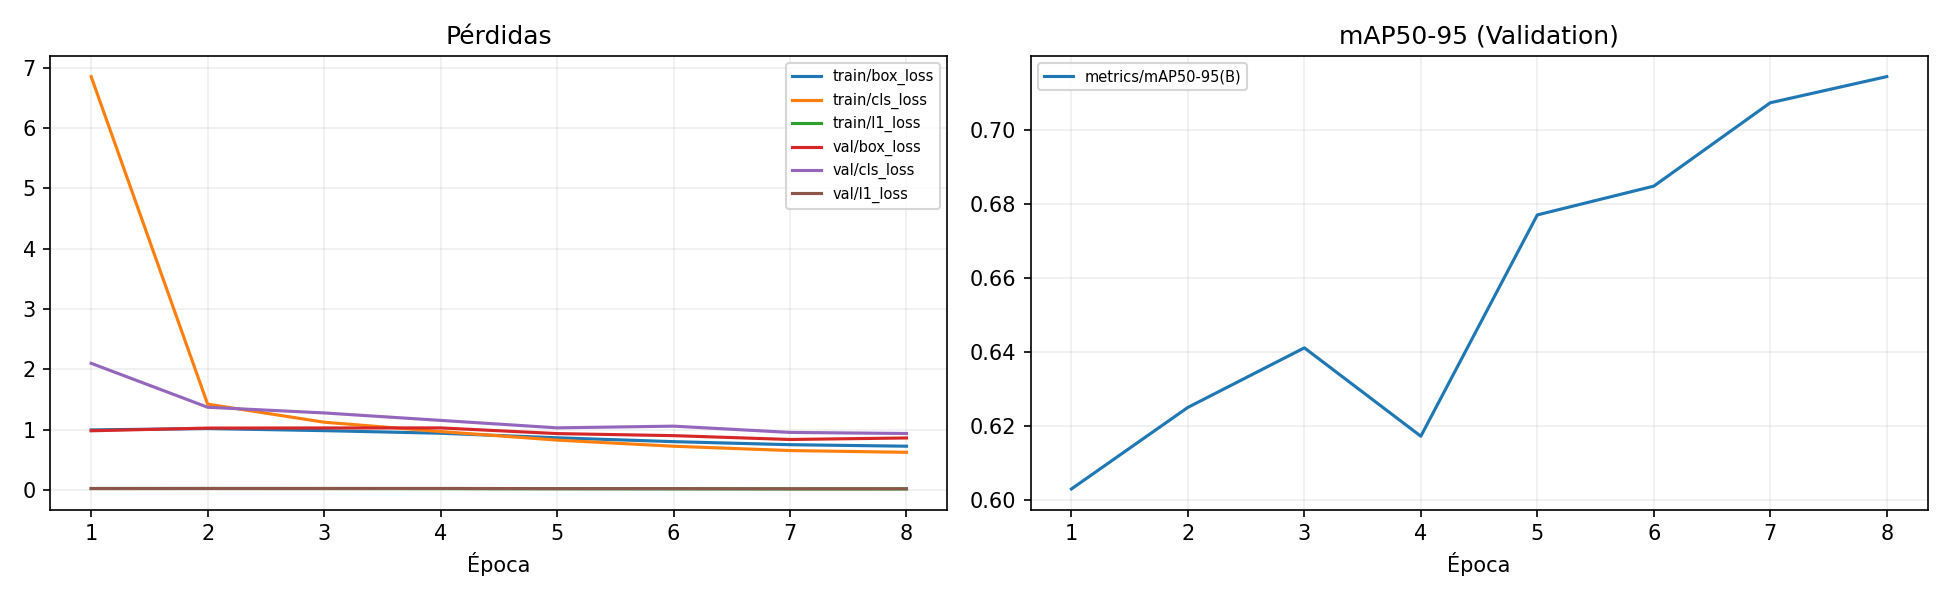

In [6]:
transfer = train_stage(BASE_WEIGHTS, DATA_YAML, "transfer_learning", EPOCHS_TRANSFER,
                       IMGSZ, BATCH, freeze=10, lr0=0.01, optimizer="auto",
                       fraction=TRAIN_FRACTION, project="/content/yolo_runs", seed=SEED)
shutil.copy2(transfer["best"], "models/transfer_learning.pt")
print(json.dumps(transfer, indent=2))
plot_training_curves(transfer["results_csv"], "results/transfer_curves.png")
display(Image(filename="results/transfer_curves.png"))

## 6 — Fine tuning obligatorio
Reanudar desde el **best.pt obtenido por nosotros**; `freeze=0`, AdamW y tasa de aprendizaje baja.

[Salida abreviada para GitHub. Registro y pesos íntegros en la exportación de Colab.]
 16                  -1  1     34304  ultralytics.nn.modules.block.C3k2            [256, 64, 1, True]            
 17                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
 18            [-1, 13]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 19                  -1  1     95232  ultralytics.nn.modules.block.C3k2            [192, 128, 1, True]           
 20                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
 21            [-1, 10]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 22                  -1  1    463104  ultralytics.nn.modules.block.C3k2            [384, 256, 1, True, 0.5, True]
 23        [16, 19, 22]  1    242346  ultralytics.nn.modules.head.Detect           [3, 1, True, [64, 128, 256]]  
YO

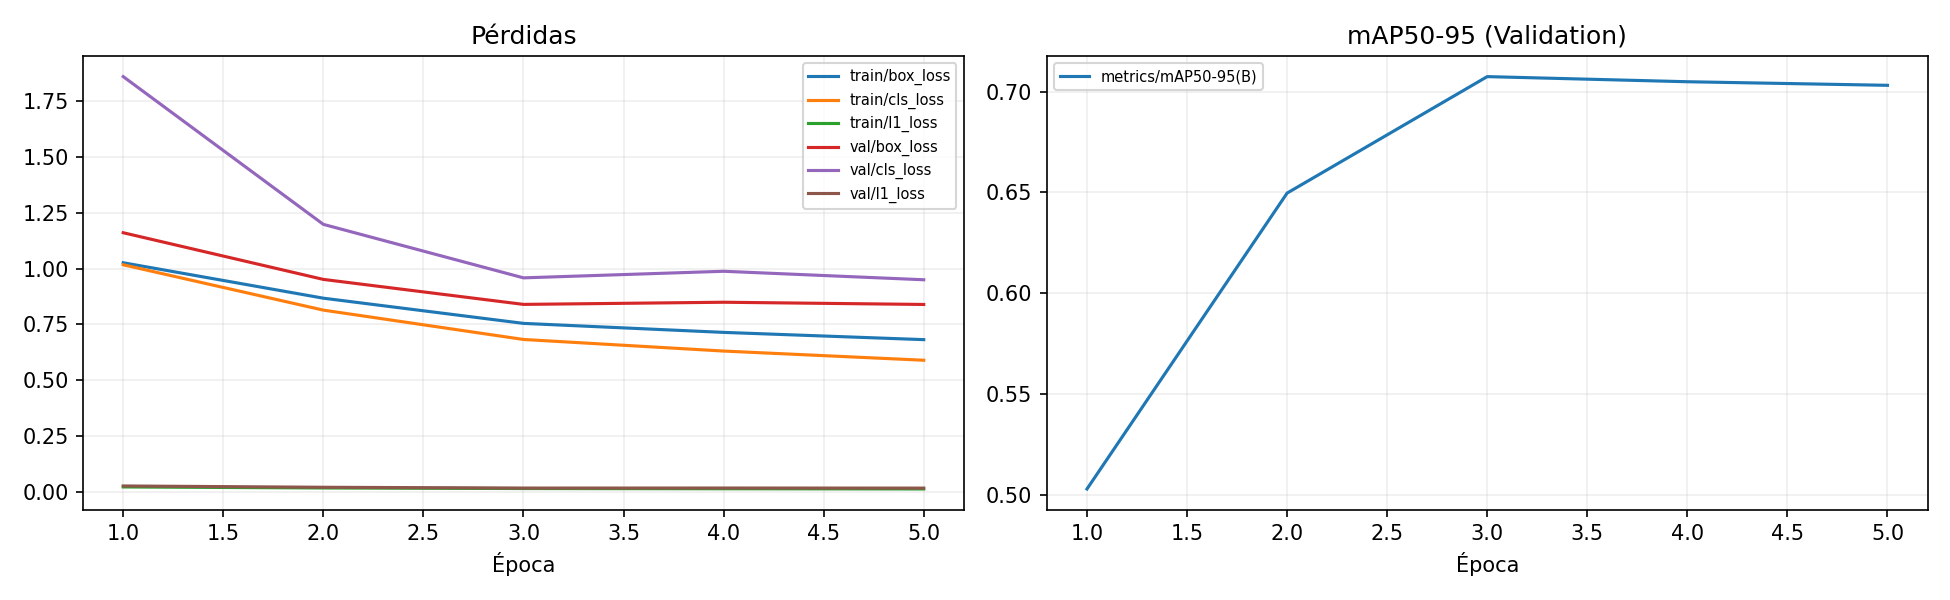

670

In [7]:
fine = train_stage(transfer["best"], DATA_YAML, "fine_tuning", EPOCHS_FINETUNE,
                   IMGSZ, BATCH, freeze=0, lr0=0.0001, optimizer="AdamW",
                   fraction=TRAIN_FRACTION, project="/content/yolo_runs", seed=SEED)
shutil.copy2(fine["best"], "models/fine_tuning.pt")
print(json.dumps(fine, indent=2))
plot_training_curves(fine["results_csv"], "results/fine_curves.png")
display(Image(filename="results/fine_curves.png"))
Path("results/train_config.json").write_text(json.dumps({"transfer":transfer,"fine_tuning":fine}, indent=2))

## 7 — Validation: medir los dos modelos
Registrar precision, recall, mAP50 y mAP50-95. **Todavía no abrir Test**.

In [8]:
val_transfer = evaluate("models/transfer_learning.pt", DATA_YAML, split="val", imgsz=IMGSZ)
val_fine = evaluate("models/fine_tuning.pt", DATA_YAML, split="val", imgsz=IMGSZ)
import pandas as pd
comparison = pd.DataFrame([{"modelo":"transfer_learning",**val_transfer},{"modelo":"fine_tuning",**val_fine}])
display(comparison)
comparison.to_csv("results/validation_comparison.csv", index=False)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1384.5±513.7 MB/s, size: 28.7 KB)
val: Scanning /content/yolo_processed/val/labels.cache... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 54.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.9it/s 3.2s
                   all        144        210      0.886      0.801      0.871      0.713
            EXCAVATORS         32         35      0.805      0.857       0.85      0.684
            dump truck         88        120      0.897      0.725      0.857      0.683
          wheel loader         52         55      0.958       0.82      0.906      0.772
Speed: 1.9ms preprocess, 4.5ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/YOLO-Maquinaria-UBO/run

,modelo,precision,recall,mAP50,mAP50_95
0,transfer_learning,0.886345,0.800567,0.870787,0.712923
1,fine_tuning,0.831851,0.834979,0.874891,0.707573


## 8 — Elección ANTES de Test
Regla escrita de antemano: máximo mAP50-95 en Validation; desempate mAP50 y luego transfer learning. La elección queda guardada y no se puede sobrescribir accidentalmente.

In [9]:
selection = select_model(val_transfer, val_fine, output="results/selection.json")
chosen_path = "models/fine_tuning.pt" if selection["selected"] == "fine_tuning" else "models/transfer_learning.pt"
shutil.copy2(chosen_path, "models/modelo_elegido.pt")
print(json.dumps(selection, indent=2))
from ultralytics import YOLO
for model_path in ["models/transfer_learning.pt","models/fine_tuning.pt","models/modelo_elegido.pt"]:
    loaded = YOLO(model_path)
    print("Pesos verificados:", model_path, loaded.names)

{
  "selected": "transfer_learning",
  "rule": "max Validation mAP50-95; empate mAP50; empate transfer",
  "transfer_validation": {
    "precision": 0.8863448906891586,
    "recall": 0.8005672952237769,
    "mAP50": 0.8707868728715517,
    "mAP50_95": 0.7129232515028179
  },
  "fine_validation": {
    "precision": 0.8318507895881592,
    "recall": 0.8349787491994886,
    "mAP50": 0.8748912836566026,
    "mAP50_95": 0.7075731544810682
  }
}
Pesos verificados: models/transfer_learning.pt {0: 'EXCAVATORS', 1: 'dump truck', 2: 'wheel loader'}
Pesos verificados: models/fine_tuning.pt {0: 'EXCAVATORS', 1: 'dump truck', 2: 'wheel loader'}
Pesos verificados: models/modelo_elegido.pt {0: 'EXCAVATORS', 1: 'dump truck', 2: 'wheel loader'}


## 9 — Aciertos, detecciones falsas y objetos perdidos en Validation
Matching por clase, IoU ≥ 0.50, umbral de confianza 0.25. Conteos educativos TP/FP/FN (no sustituye evaluación mAP Ultralytics).

In [10]:
val_counts = count_detections("models/modelo_elegido.pt", DATA_YAML, split="val",
                              imgsz=IMGSZ, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD)
print(json.dumps(val_counts, indent=2, ensure_ascii=False))
Path("results/validation_counts.json").write_text(json.dumps(val_counts, indent=2, ensure_ascii=False))

{
  "counts": {
    "TP": 165,
    "FP": 35,
    "FN": 45
  },
  "confidence_threshold": 0.25,
  "iou_threshold": 0.5,
  "examples": {
    "false_positive": [
      "/content/yolo_processed/val/images/construction--1023-_jpg.rf.7a3952796d5b545c63d553911fff9214.jpg",
      "/content/yolo_processed/val/images/construction--1059-_jpg.rf.1a8068483d6b283de149f09e69220830.jpg",
      "/content/yolo_processed/val/images/construction--1074-_jpg.rf.160dbb91652803fa2d89f46e5843c68b.jpg",
      "/content/yolo_processed/val/images/construction--1223-_jpg.rf.5ac34ff377b1d0006b34e2c131575b40.jpg",
      "/content/yolo_processed/val/images/construction--184-_jpg.rf.576bc32ec63d3ca44a56aed84a11640a.jpg"
    ],
    "missed": [
      "/content/yolo_processed/val/images/construction--1022-_jpg.rf.0f8fbf1c01af59e01230fb308bf40ffa.jpg",
      "/content/yolo_processed/val/images/construction--1074-_jpg.rf.160dbb91652803fa2d89f46e5843c68b.jpg",
      "/content/yolo_processed/val/images/construction--134-_jpg

1267

## 10 — Test final (SOLO UNA VEZ)
**Ejecutar una única vez** después de la elección. La función crea un marcador para bloquear una segunda evaluación, incluso si el resultado es malo. No usar Test para cambiar hiperparámetros.

In [11]:
test_metrics = test_once("models/modelo_elegido.pt", DATA_YAML, imgsz=IMGSZ,
                         output="results/test_metrics.json")
print("Resultados TEST — no volver a ejecutar:", json.dumps(test_metrics, indent=2))

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1403.0±738.1 MB/s, size: 38.1 KB)
val: Scanning /content/yolo_processed/test/labels... 82 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 82/82 2.0Kit/s 0.0s
val: New cache created: /content/yolo_processed/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.0it/s 2.0s
                   all         82        127      0.901      0.771      0.866      0.717
            EXCAVATORS         15         17      0.848      0.765      0.864      0.699
            dump truck         56         80       0.95      0.713      0.839      0.685
          wheel loader         27         30      0.906      0.833      0.894      0.766
Speed: 2.2ms preprocess, 4.3ms inference, 0.0ms loss, 4.1ms postprocess pe

## 11 — Análisis cualitativo en Test
La galería permite comparar las etiquetas reales y predicciones del modelo. Seleccionar y comentar **tres fallos**: objeto perdido, falsa detección y caja mal posicionada o clase confundida.

**Evidencia conservada:** [Galería original de Test con cajas reales y predichas](https://github.com/MamatorHack/YOLO-Maquinaria-UBO/blob/main/assets/figures/test_gallery.png). El código sigue generando la imagen completa al ejecutarse.

In [12]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from ultralytics import YOLO
model = YOLO("models/modelo_elegido.pt")
test_images = sorted(p for p in Path("/content/yolo_processed/test/images").rglob("*") if p.suffix.lower() in IMAGE_EXTS)[:6]
fig, axs = plt.subplots(len(test_images), 2, figsize=(12, max(4, 4*len(test_images))))
axs = np.asarray(axs).reshape(-1, 2)
for row, p in zip(axs, test_images):
    from matplotlib.patches import Rectangle
    original = PILImage.open(p).convert("RGB")
    width, height = original.size
    row[0].imshow(original)
    label_file = Path("/content/yolo_processed/test/labels") / p.relative_to(Path("/content/yolo_processed/test/images")).with_suffix(".txt")
    if label_file.exists():
        for ln in label_file.read_text().splitlines():
            cls,x,y,w,h = map(float, ln.split())
            row[0].add_patch(Rectangle(((x-w/2)*width,(y-h/2)*height), w*width,h*height, fill=False,edgecolor="lime",linewidth=2))
            row[0].text((x-w/2)*width,(y-h/2)*height,CLASES[int(cls)],color="black",backgroundcolor="lime",fontsize=7)
    row[0].set_title("Cajas REALES: "+p.name[:28]); row[0].axis("off")
    prediction = model.predict(str(p), imgsz=IMGSZ, conf=CONF_THRESHOLD, verbose=False)[0]
    row[1].imshow(prediction.plot()[:,:,::-1]); row[1].set_title("Predicciones YOLO"); row[1].axis("off")
plt.tight_layout(); plt.savefig("results/test_gallery.png", dpi=140); plt.show()
print("Galería real vs predicho guardada. Seleccionar 3 errores distintos y explicarlos en el PDF.")

Galería real vs predicho guardada. Seleccionar 3 errores distintos y explicarlos en el PDF.


### Análisis cualitativo de errores
Se registran predicciones de clase equivocada y falsas detecciones en las muestras de Test. Identificar los casos con su imagen correspondiente:
- Confusión: vista aérea de `wheel loader` detectada adicionalmente como `EXCAVATORS` con confianza 0,44.
- Falsa detección: parte de una `wheel loader` identificada como `dump truck` con confianza 0,26.
- Objeto perdido: revisar los ejemplos de Validation registrados en `results/validation_counts.json` y marcar una imagen Test si se pretende usar ese split como ejemplo; no modificar el modelo tras mirar Test.
Las imágenes del informe deben citar exactamente el conjunto (Validation o Test) donde se observó cada error.

## 12 — Predicciones externas al dataset (2 fotos y 2 videos)
Las dos fotografías externas se tomaron de Pexels; la inferencia detectó una `wheel loader` en la primera y una `EXCAVATORS` más `dump truck` en la segunda. Se procesaron dos videos de obras diferentes a 720p/10 fps con `stream=True`, evitando desbordar la RAM: **245 y 199 cuadros**. Los clips anotados completos se conservan en el ZIP de evidencias del equipo; no se incluyen en el notebook por su tamaño. Las fuentes y el límite de esta evaluación están descritos en el informe.

In [13]:
from google.colab import files
print("Subir imágenes externas (JPG/PNG), opcional en esta celda")
ext = files.upload()
Path("external/images").mkdir(parents=True, exist_ok=True)
for filename in ext:
    if Path(filename).suffix.lower() in IMAGE_EXTS:
        shutil.move(filename, str(Path("external/images") / Path(filename).name))
external_images = [str(p) for p in Path("external/images").rglob("*") if p.suffix.lower() in IMAGE_EXTS]
if external_images:
    model.predict(source=external_images, imgsz=IMGSZ, conf=CONF_THRESHOLD,
                  save=True, project="/content/YOLO-Maquinaria-UBO/results", name="external_images", exist_ok=True)
else:
    print("SIN IMÁGENES EXTERNAS. Este apartado aún no está cumplido.")

Subir imágenes externas (JPG/PNG), opcional en esta celda


Saving pexels-rohanbatra-40537857.jpg to pexels-rohanbatra-40537857.jpg
Saving pexels-celalkeser-36506004.jpg to pexels-celalkeser-36506004.jpg

0: 416x416 1 wheel loader, 27.4ms
1: 416x416 1 EXCAVATORS, 1 dump truck, 27.4ms
Speed: 1.8ms preprocess, 27.4ms inference, 1.1ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/YOLO-Maquinaria-UBO/results/external_images


In [2]:
from google.colab import files
from pathlib import Path
import gc, subprocess, torch, cv2
from ultralytics import YOLO
ROOT = Path("/content/YOLO-Maquinaria-UBO")
video_dir = ROOT / "external/videos"
video_dir.mkdir(parents=True, exist_ok=True)
video = video_dir / "16517436_3840_2160_30fps.mp4"
if not video.exists():
    print("Subir video externo 1 (al menos 10 segundos)")
    uploaded = files.upload()
    candidatos = [k for k in uploaded if Path(k).suffix.lower() in {".mp4", ".mov", ".avi"}]
    assert len(candidatos) == 1
    video = video_dir / Path(candidatos[0]).name
    import shutil
    shutil.move(candidatos[0], video)
weights = ROOT / "models/modelo_elegido.pt"
assert weights.exists(), "Restaurar los pesos entrenados antes de la predicción"
cap = cv2.VideoCapture(str(video))
fps, frames = cap.get(cv2.CAP_PROP_FPS), cap.get(cv2.CAP_PROP_FRAME_COUNT)
cap.release()
assert fps > 0 and frames/fps >= 10, "Video inválido o de menos de 10 segundos"
video_720 = video_dir / "video_1_720p.mp4"
subprocess.run(["ffmpeg","-y","-hide_banner","-loglevel","error","-i",str(video),
                "-vf","scale=-2:720,fps=10","-an","-c:v","libx264",
                "-preset","ultrafast",str(video_720)],check=True)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
detector = YOLO(str(weights))
frames_processed = 0
for resultado in detector.predict(source=str(video_720),imgsz=416,conf=0.25,
                                  stream=True,save=True,verbose=False,
                                  project=str(ROOT/"results"),name="video_1_streaming",exist_ok=True):
    frames_processed += 1
    if frames_processed % 50 == 0:
        print(f"{frames_processed} fotogramas procesados")
    del resultado
print(f"Video 1: {frames_processed} fotogramas. Guardado en results/video_1_streaming")

50 images traitées
100 images traitées
150 images traitées
200 images traitées
Results saved to /content/YOLO-Maquinaria-UBO/results/video_1_streaming
Terminé : 245 images traitées !
Vidéo annotée : /content/YOLO-Maquinaria-UBO/results/video_1_streaming


In [4]:
from google.colab import files
from pathlib import Path
import gc, subprocess, torch, cv2
from ultralytics import YOLO
ROOT = Path("/content/YOLO-Maquinaria-UBO")
video_dir = ROOT / "external/videos"
video_dir.mkdir(parents=True, exist_ok=True)
video = video_dir / "16499298_3840_2160_30fps.mp4"
if not video.exists():
    print("Subir video externo 2 (al menos 10 segundos)")
    uploaded = files.upload()
    candidatos = [k for k in uploaded if Path(k).suffix.lower() in {".mp4", ".mov", ".avi"}]
    assert len(candidatos) == 1
    video = video_dir / Path(candidatos[0]).name
    import shutil
    shutil.move(candidatos[0], video)
weights = ROOT / "models/modelo_elegido.pt"
assert weights.exists(), "Restaurar los pesos entrenados antes de la predicción"
cap = cv2.VideoCapture(str(video))
fps, frames = cap.get(cv2.CAP_PROP_FPS), cap.get(cv2.CAP_PROP_FRAME_COUNT)
cap.release()
assert fps > 0 and frames/fps >= 10, "Video inválido o de menos de 10 segundos"
video_720 = video_dir / "video_2_720p.mp4"
subprocess.run(["ffmpeg","-y","-hide_banner","-loglevel","error","-i",str(video),
                "-vf","scale=-2:720,fps=10","-an","-c:v","libx264",
                "-preset","ultrafast",str(video_720)],check=True)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
detector = YOLO(str(weights))
frames_processed = 0
for resultado in detector.predict(source=str(video_720),imgsz=416,conf=0.25,
                                  stream=True,save=True,verbose=False,
                                  project=str(ROOT/"results"),name="video_2_streaming",exist_ok=True):
    frames_processed += 1
    if frames_processed % 50 == 0:
        print(f"{frames_processed} fotogramas procesados")
    del resultado
print(f"Video 2: {frames_processed} fotogramas. Guardado en results/video_2_streaming")

50 images traitées
100 images traitées
150 images traitées
Results saved to /content/YOLO-Maquinaria-UBO/results/video_2_streaming
Terminé : 199 images traitées !
Vidéo annotée : /content/YOLO-Maquinaria-UBO/results/video_2_streaming


## 13 — Respaldo de resultados y pesos
Se entrega por separado el notebook ejecutado, el PDF (máximo 10 páginas sin portada ni anexos) y los archivos `transfer_learning.pt`, `fine_tuning.pt`, `modelo_elegido.pt`. Esta celda empaqueta resultados, videos anotados y pesos. Es normal que el ZIP completo sea grande; descargarlo antes de cerrar Colab.

In [5]:

from pathlib import Path
import shutil
import zipfile
from google.colab import files

ROOT = Path("/content/YOLO-Maquinaria-UBO")

# Vérifier que les 3 modèles entraînés existent
modeles = [
    "transfer_learning.pt",
    "fine_tuning.pt",
    "modelo_elegido.pt"
]

for nom in modeles:
    chemin = ROOT / "models" / nom
    print(f"{'✅' if chemin.exists() else '❌'} {nom}")

manquants = [
    nom for nom in modeles
    if not (ROOT / "models" / nom).exists()
]

if manquants:
    raise FileNotFoundError(
        "Modèles introuvables : " + ", ".join(manquants)
    )

# Créer une archive avec résultats et modèles
archive = "/content/YOLO_E03_resultados.zip"

with zipfile.ZipFile(
    archive, "w", zipfile.ZIP_DEFLATED
) as z:

    # Résultats et prédictions
    dossier = ROOT / "results"
    if dossier.exists():
        for p in dossier.rglob("*"):
            if p.is_file():
                z.write(p, p.relative_to(ROOT))

    # Les trois modèles
    for nom in modeles:
        p = ROOT / "models" / nom
        z.write(p, f"models/{nom}")

    # Courbes et configurations des entraînements
    for phase in ["transfer_learning", "fine_tuning"]:
        dossier = Path("/content/yolo_runs") / phase
        for nom in ["results.csv", "results.png", "args.yaml"]:
            p = dossier / nom
            if p.exists():
                z.write(p, f"training/{phase}/{nom}")

print("✅ Archive créée :", archive)
print("Taille :", round(Path(archive).stat().st_size / 1024**2, 2), "Mo")

files.download(archive)

✅ transfer_learning.pt
✅ fine_tuning.pt
✅ modelo_elegido.pt
✅ Archive créée : /content/YOLO_E03_resultados.zip
Taille : 508.61 Mo
